In [ ]:
# 1. LIBRERÍAS
import numpy as np
import os # sirve para interactuar con el sistema de archivos y directorios del sistema operativo
from PIL import Image # con esto importamos la librería de imágenes que sirve para abrir, manipular y guardar imágenes en diferentes formatos
import matplotlib.pyplot as plt

In [ ]:
# 2. FUNCIÓN (AUTOMÁTICA POR CARPETAS)
# Esta función recorre las carpetas de un directorio, carga las imágenes, las redimensiona y normaliza, 
# y asigna etiquetas basadas en el nombre de la carpeta.
def cargar_dataset(base_dir, img_size=(150,150)):
    imagenes = []
    etiquetas = []

    for clase in os.listdir(base_dir):
        ruta_clase = os.path.join(base_dir, clase)

        if os.path.isdir(ruta_clase):
            for archivo in os.listdir(ruta_clase):
                if archivo.lower().endswith(('.jpg','.jpeg','.png')): # Verifica que el archivo sea una imagen para evitar errores  

                    ruta = os.path.join(ruta_clase, archivo)

                    img = Image.open(ruta) # Carga la imagen
                    img = img.resize(img_size) # Redimensiona la imagen al tamaño especificado
                    img = np.array(img) / 255.0 #  Normaliza los valores de píxeles a [0,1], 250 es debido a que los valores de píxeles van de 0 a 255, y al dividirlo por 255.0 se obtiene un rango de 0 a 1

                    imagenes.append(img)
                    etiquetas.append(clase)

    return np.array(imagenes), np.array(etiquetas) # finalmente guarda todas las imagenes en una lista y todas las etiquetas en otra

In [3]:
# 3. Lectura de la ruta
base_dir = r"C:\Users\Acer\Desktop\UPB\Inteligencia artificial 2026-02\Clases\Clase 26\banana_classification"

In [ ]:
# 4. CARGAR DATOS
X, Y = cargar_dataset(base_dir)

print("Shape:", X.shape)
print("Ejemplo etiquetas:", Y[:10])

# Nos arroja que son 2400 imagenes (600 por cada categoría) , 150x 150 pixeles , y 3 canales (RGB) por ser imagenes a color

Shape: (2400, 150, 150, 3)
Ejemplo etiquetas: ['overripe' 'overripe' 'overripe' 'overripe' 'overripe' 'overripe'
 'overripe' 'overripe' 'overripe' 'overripe']


In [ ]:
# 5. CODIFICAR ETIQUETAS
# En este proceso se utiliza LabelEncoder para convertir las etiquetas de texto en números enteros, 
# lo que es necesario para el entrenamiento del modelo. Es decir, cada categoría queda con un número asignado
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y)

print("Clases:", labelencoder.classes_)

Clases: ['overripe' 'ripe' 'rotten' 'unripe']


In [6]:
# 6. SPLIT
# Aquí se divide el conjunto de datos en entrenamiento y prueba utilizando train_test_split de sklearn,
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

## MODELO BASE

In [7]:
# configuración del modelo base
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout
import tensorflow as tf

tf.random.set_seed(3) # Para asegurar la reproducibilidad de los resultados, se establece una semilla para el generador de 
#números aleatorios de TensorFlow. Esto garantiza que cada vez que se ejecute el código, se obtendrán los mismos resultados, 
# lo cual es crucial para la depuración y comparación de modelos.
np.random.seed(3) # Establece la semilla para el generador de números aleatorios de NumPy, lo que asegura que las operaciones aleatorias 
# de NumPy produzcan los mismos resultados en cada ejecución del código.

modelo = Sequential() # Se crea un modelo secuencial, que es una pila lineal de capas. Esto permite construir el modelo añadiendo 
#capas de manera secuencial.

# Capas convolucionales y de pooling para extraer características de las imágenes.
modelo.add(Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3))) # Agrega una capa convolucional con 32 filtros de tamaño 3x3, función de activación ReLU y especifica la forma de entrada de las imágenes (150x150 píxeles con 3 canales de color).
modelo.add(MaxPooling2D(2,2)) # Agrega una capa de pooling que reduce la dimensionalidad de las características extraídas por la capa convolucional, utilizando un tamaño de ventana de 2x2.

# Capa flatten para convertir las características extraídas en un vector unidimensional, seguido de una capa de dropout para prevenir el sobreajuste.
modelo.add(Flatten())

# Capas densas para la clasificación final.
modelo.add(Dense(100, activation='relu'))
modelo.add(Dense(4, activation='softmax'))

# Commpilador del modelo con el optimizador Adam, la función de pérdida de entropía cruzada categórica y la métrica de precisión.
modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = modelo.fit(X_train, y_train, epochs=20, batch_size=8)

c:\Users\Acer\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 67s 267ms/step - accuracy: 0.5938 - loss: 2.1706
Epoch 2/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 65s 271ms/step - accuracy: 0.7917 - loss: 0.5315
Epoch 3/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 87s 290ms/step - accuracy: 0.8516 - loss: 0.3994
Epoch 4/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 62s 256ms/step - accuracy: 0.8854 - loss: 0.3016
Epoch 5/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 67s 279ms/step - accuracy: 0.9094 - loss: 0.2628
Epoch 6/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 71s 294ms/step - accuracy: 0.9312 - loss: 0.2056
Epoch 7/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 69s 237ms/step - accuracy: 0.9552 - loss: 0.1439
Epoch 8/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 66s 275ms/step - accuracy: 0.9630 - loss: 0.1204
Epoch 9/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 73s 236ms/step - accuracy: 0.9625 - loss: 0.1132
Epoch 10/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 55s 228ms/step - accuracy: 0.9740 - loss: 0.0764
Epoch 11/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 74s 308ms/step - accuracy: 0.9807 - loss: 0.0607
Epoch 12/20
240/240

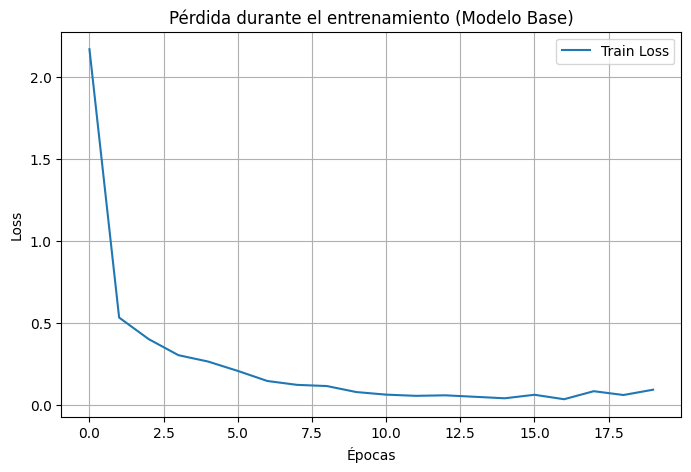

In [8]:
# Gráfica de la pérdida durante el entrenamiento del modelo base.
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

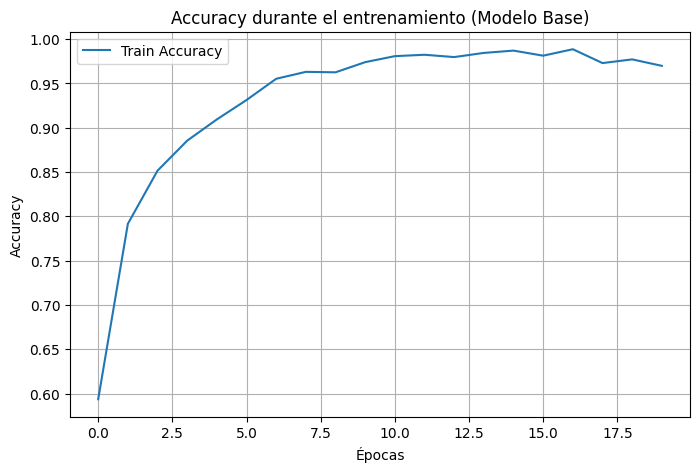

In [9]:
# Gráfica del accuracy durante el entrenamiento del modelo base.
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [10]:
# Métricas de evaluación para el modelo base utilizando accuracy_score y f1_score de sklearn.
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 88ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step
===== TRAIN =====
Accuracy: 0.9578125
F1-score: 0.9582805685878665

===== TEST =====
Accuracy: 0.75625
F1-score: 0.7463197559512716


* Desempeño altísimo en el conjunto de entrenamiento (95%) mientras que hay una diferenca grande de casi 20% vs el conjunto de test, lo que indica overfitting claro, el modelo memorizó los datos, una de las posibles razones es la baja cantidad de datos de entrenamiento, 600 imagenes por clase.

* Para evitar el overitting se usa diferentes tipos de técnicas como:
* Data Augmentation: en donde se crean imagenes con pequeñas modificaciones, aumentando el data set y haciendo que el modelo generalice mejor sin memorizar los datos.
* Dropout: Apaga un % de neuronas diferentes de forma aleatoria en cada epoch, esto hace que todas las neuronas tengan que aprender si o si y no le dejan todo el trabajo a solo algunas.
* BatchNormalization:  Estabiliza los valores dentro de la red, ya que a medida que los datos pasan por las capas de una red neuronal, los valores se van multiplicando por pesos y sumando sesgos. Esto puede generar que al llegar a capas profundas, los números pueden volverse muy grandes, o muy pequeños, entonces el batch normaliza los datos capa tras capa para pasarlos a una media de 0 y una desviación estandar de 1



## MODELO CNN OPTIMIZADO

In [11]:
# AUMENTO DE DATOS
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_generator = ImageDataGenerator(
    shear_range=0.2, #las imágenes pueden ser deformadas hasta un 20%
    zoom_range=0.2, #las imágenes pueden aumentarse hasta un 20% en su tamaño original.
    horizontal_flip=True, #voltear horizontalmente las imágenes de manera aleatoria durante el entrenamiento
    rotation_range=20, #rotacion de las imágenes (20 grados)
    fill_mode='nearest' # Rellena los píxeles fuera de los límites de la imagen con los valores más cercanos
)

In [12]:
# Configuración del modelo optimizado con capas adicionales de convolución, normalización y dropout para mejorar el rendimiento.
from tensorflow.keras import layers

modelo_opt = Sequential() # Se crea un nuevo modelo secuencial para el modelo optimizado, que permitirá construir una arquitectura más compleja añadiendo capas de manera secuencial.

# Capas convolucionales con normalización por lotes y activación ReLU para mejorar la capacidad de extracción de características, seguidas de capas de pooling para reducir la dimensionalidad.
modelo_opt.add(Conv2D(16, (3,3), input_shape=(150,150,3))) 
modelo_opt.add(layers.BatchNormalization()) # La normalización por lotes ayuda a estabilizar y acelerar el entrenamiento al normalizar las activaciones de la capa anterior, lo que puede mejorar la convergencia del modelo.
modelo_opt.add(layers.Activation('relu')) # La función de activación ReLU introduce no linealidad en el modelo, lo que permite aprender relaciones más complejas entre las características extraídas por la capa convolucional.
modelo_opt.add(MaxPooling2D(2,2)) # Agrega una capa de pooling que reduce la dimensionalidad de las características extraídas por la capa convolucional, utilizando un tamaño de ventana de 2x2.

modelo_opt.add(Conv2D(32, (3,3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# capa flatten para convertir las características extraídas en un vector unidimensional, seguido de capas densas con dropout para prevenir el sobreajuste y mejorar la capacidad de generalización del modelo.
modelo_opt.add(Flatten())

# Capas densas para la clasificación final, con dropout para prevenir el sobreajuste.
modelo_opt.add(Dense(128, activation='relu'))
modelo_opt.add(Dropout(0.2))

modelo_opt.add(Dense(64, activation='relu'))
modelo_opt.add(Dropout(0.2))

modelo_opt.add(Dense(4, activation='softmax'))

modelo_opt.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

c:\Users\Acer\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
history_opt = modelo_opt.fit(
    train_generator.flow(X_train, y_train, batch_size=16),
    epochs=20
)

Epoch 1/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 46s 303ms/step - accuracy: 0.5000 - loss: 2.2884
Epoch 2/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 41s 339ms/step - accuracy: 0.6307 - loss: 0.9096
Epoch 3/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 39s 319ms/step - accuracy: 0.6495 - loss: 0.9080
Epoch 4/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 39s 322ms/step - accuracy: 0.7052 - loss: 0.7964
Epoch 5/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 37s 309ms/step - accuracy: 0.7302 - loss: 0.7628
Epoch 6/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 43s 355ms/step - accuracy: 0.7328 - loss: 0.7223
Epoch 7/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 35s 289ms/step - accuracy: 0.7469 - loss: 0.6998
Epoch 8/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 37s 308ms/step - accuracy: 0.7193 - loss: 0.7295
Epoch 9/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 36s 296ms/step - accuracy: 0.7682 - loss: 0.6472
Epoch 10/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 35s 292ms/step - accuracy: 0.7583 - loss: 0.6711
Epoch 11/20
120/120 ━━━━━━━━━━━━━━━━━━━━ 33s 276ms/step - accuracy: 0.8047 - loss: 0.5869
Epoch 12/20
120/120

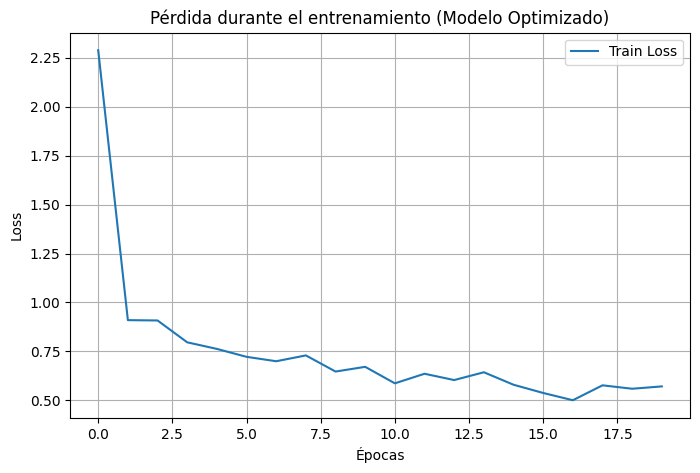

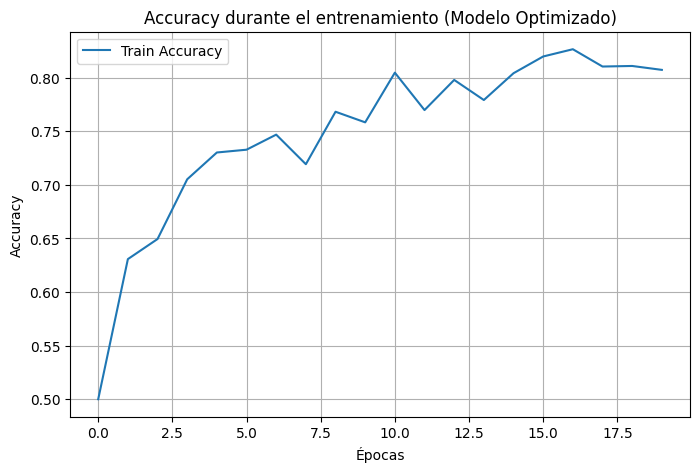

In [14]:
import matplotlib.pyplot as plt

# =========================
# LOSS
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# =========================
# ACCURACY
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [15]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo_opt.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo_opt.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step
===== TRAIN =====
Accuracy: 0.8838541666666667
F1-score: 0.8829390541053942

===== TEST =====
Accuracy: 0.8875
F1-score: 0.8854095185467884


El modelo optimizado tiene mucho menos sobreajuste observado. Esto indica una mejor capacidad de generalización, lograda mediante el uso de diferentes técnicas.

cómo podriamos mejorar aún mas el modelo?

* Obtener mas datos, 600 imagenes por clase en problemas de CNN, suelen ser muy pocos, entre mas datos y de mas calidad mucho mejor y mas sencillo será para la red neuronal entender y encontrar patrone.

* Colocar mas parámetros en data augmentation
train_generator = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    zoom_range=0.25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    brightness_range=[0.7, 1.3],  
    horizontal_flip=True

* Aumetar la complejidad del mdelo, pero de forma controlada, aumentarlo de a poco, una capa mas, unas cuantas neuronas mas por capa, nunca aumentar desproporcionadamente

* Usar early stopping: Es un tipo de freno de emergencia, donde el modelo deja de entrenar cuando deja de aprender y comienza a memorizar

* Aumentar resolución, en este ejemplo se usó 150 x 150, si aumentamos la resolución podriamos tener mejores resultados


In [16]:
# GUARDAR EL MODELO
modelo_opt.save("modelo_banano.keras")

# GUARDAR EL LABEL ENCODER ya que el modelo solo guarda los pesos, no la información de las clases, 
# por lo que es necesario guardar el label encoder para poder interpretar las predicciones del modelo posteriormente.
import pickle

with open("labelencoder.pkl", "wb") as f:
    pickle.dump(labelencoder, f)

## Despliegue

In [11]:
import os
import numpy as np
from PIL import Image
import pickle
from tensorflow.keras.models import load_model

In [12]:
# cargar modelo
modelo = load_model("modelo_banano.keras")

# cargar label encoder
with open("labelencoder.pkl", "rb") as f:
    labelencoder = pickle.load(f)

In [13]:
# Debo hacer el mismo preprocesamiento que hice con las imágenes de entrenamiento, es decir, redimensionar y normalizar las imágenes antes de hacer la predicción.
def predecir_carpeta(ruta_carpeta, modelo, labelencoder, img_size=(150,150)):
    
    resultados = []

    for archivo in os.listdir(ruta_carpeta):
        if archivo.lower().endswith(('.jpg','.jpeg','.png')):
            
            ruta = os.path.join(ruta_carpeta, archivo)

            # cargar imagen
            img = Image.open(ruta)
            img = img.resize(img_size)
            img = np.array(img) / 255.0

            # agregar dimensión batch
            img = np.expand_dims(img, axis=0)

            # predicción
            pred = modelo.predict(img)
            clase_pred = np.argmax(pred, axis=1)

            # convertir a etiqueta original
            etiqueta = labelencoder.inverse_transform(clase_pred)

            resultados.append((archivo, etiqueta[0]))

    return resultados

In [14]:
ruta_nuevos = r"C:\Users\Acer\Desktop\UPB\Inteligencia artificial 2026-02\Clases\Clase 26\New data"

In [ ]:
# Predecir las clases de las nuevas imágenes en la carpeta especificada utilizando el modelo optimizado y el label encoder 
# para interpretar las predicciones.
resultados = predecir_carpeta(ruta_nuevos, modelo, labelencoder)

for archivo, pred in resultados:    
    print(f"{archivo} → {pred}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
musa-acuminata-overripe-a1951685-1d0a-11ec-b163-d8c4975e38aa_jpg.rf.00551be4d70aa01b254cafaee0a4901c.jpg → overripe
musa-acuminata-overripe-a1951685-1d0a-11ec-b163-d8c4975e38aa_jpg.rf.08c2c7ad6be40c0d906036f55d11a05c.jpg → overripe
musa-acuminata-overripe-a1951685-1d0a-11ec-b163-d8c4975e38aa_jpg.rf.7344d62b09b56984568a205517501523.jpg → overripe
musa-acuminata-ripe-95011532-1d0a-11ec-bf89-d8c4975e38aa_jpg.rf.38632a20249eda27a9b0fa2967930c47.jpg → ripe
musa-acuminata-ripe-95011532-1d0a-11ec-bf89-d8c4975e38aa_jpg.rf.4ace66b07b94701de9462a

Recordar que
0--> Overripe
1--> Ripe
2--> Rotten
3--> Unripe


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step


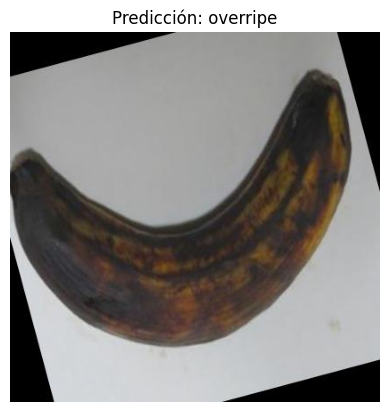

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


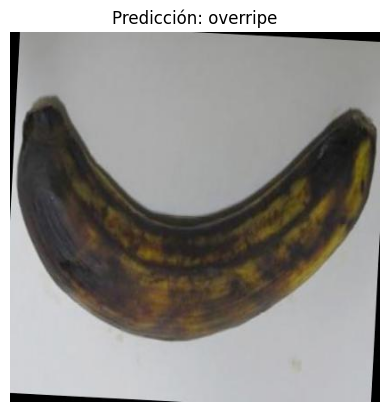

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


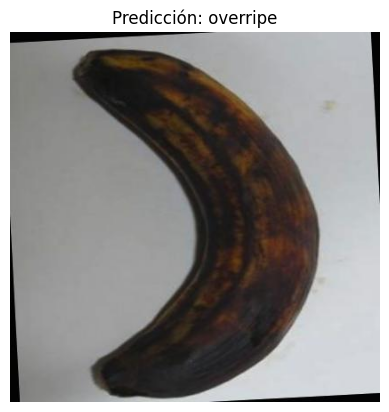

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


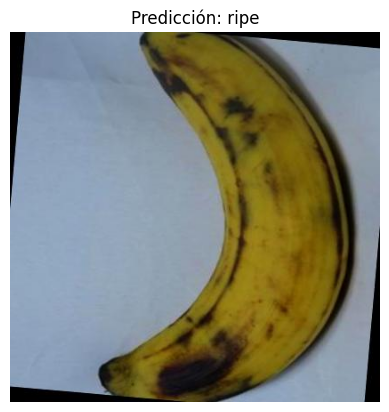

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


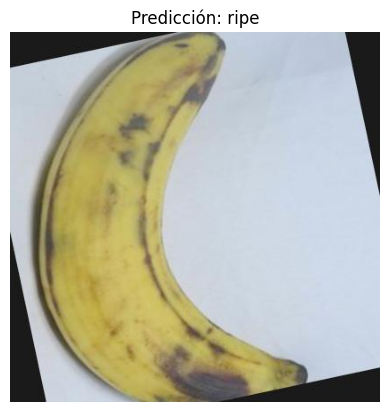

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


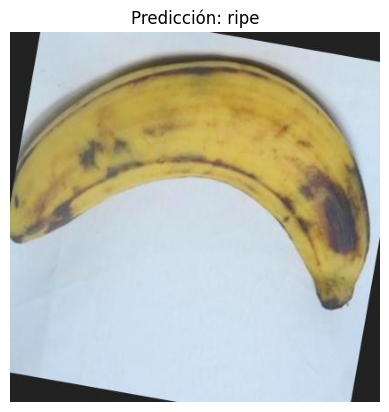

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


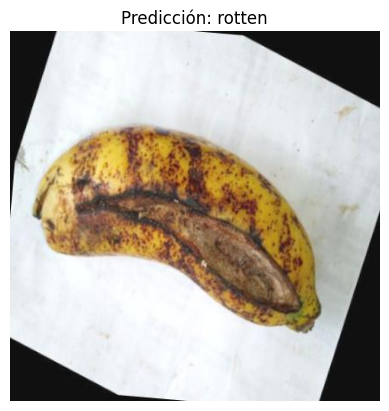

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


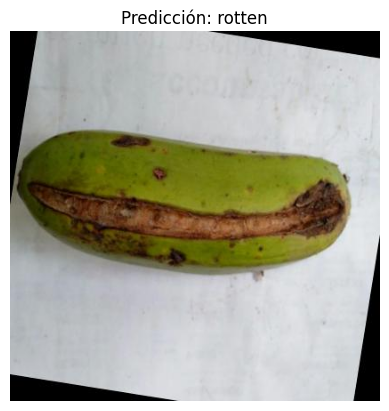

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


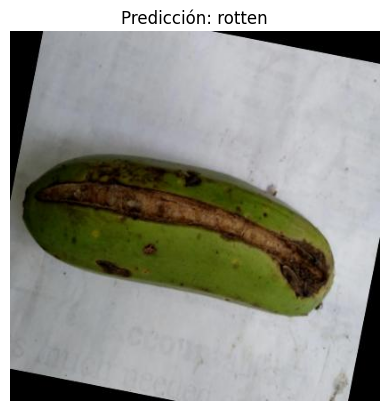

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


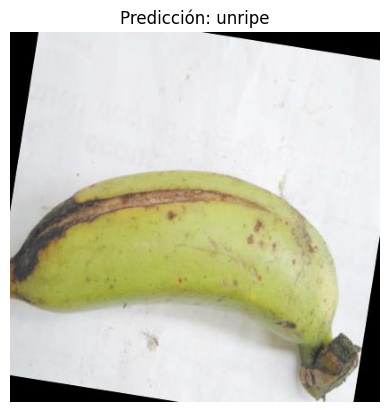

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


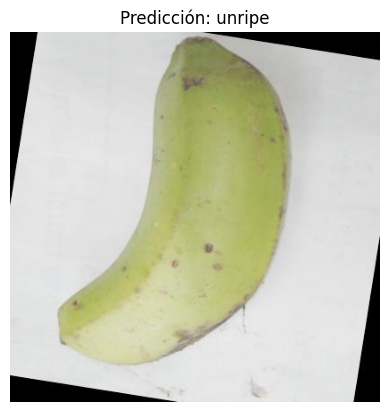

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


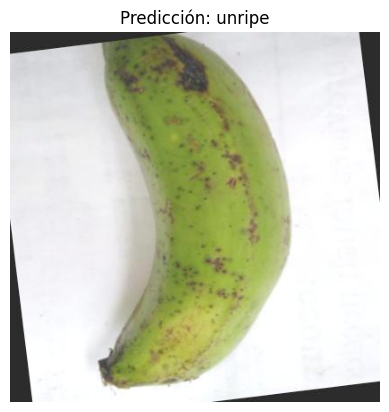

In [16]:
import matplotlib.pyplot as plt

for archivo in os.listdir(ruta_nuevos):
    if archivo.lower().endswith(('.jpg','.jpeg','.png')):
        
        ruta = os.path.join(ruta_nuevos, archivo)

        img = Image.open(ruta)

        img_array = np.array(img.resize((150,150))) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        pred = modelo.predict(img_array)
        clase = labelencoder.inverse_transform([np.argmax(pred)])

        plt.imshow(img)
        plt.title(f"Predicción: {clase[0]}")
        plt.axis("off")
        plt.show()